# Complex-Time Propagator — NN Thimble

**Goal:** compute the propagator at **complex time** $T_c = T - i\eta$:

$$K(x_f, x_i;\, T_c) = \langle x_f | e^{-iHT_c} | x_i \rangle$$

for the anharmonic oscillator, using a neural-network thimble.
The small imaginary part $\eta > 0$ damps high-energy eigenstates via
$e^{-\eta E_n}$, making the spectral sum absolutely convergent.

Results are compared against the exact Mehler kernel evaluated at $T_c$
(Chapter 8 of `PT_propagator_imag_time.ipynb`).

**Toggles** (set to `True` to re-enable later):
- `USE_WARM_START = False` — warm-start from previous weights
- `USE_LAMBDA_LADDER = False` — scan over multiple lambda values

This notebook trains a **nonlinear thimble** model
$x = A^\top z + b + g_\theta(z)$
for a single $\lambda$ value and compares the ML propagator against exact results.

In [ ]:
import torch, torch.nn as nn, numpy as np, time, csv, os, math
import scipy.linalg
import matplotlib.pyplot as plt
%matplotlib inline
 
torch.manual_seed(42)
np.random.seed(42)

## 1. Parameters

Complex-time propagator: $T_c = T - i\eta$.
Matches the PT notebook Chapter 8 defaults: $T=1$, $\omega=1$, $\eta=0.05$.
Warm-start and lambda-ladder are disabled by default via toggles.

In [ ]:
# ────────────────────────────────────────────────────────────────────
#  COMPLEX-TIME PROPAGATOR PARAMETERS
#  K(x_f, x_i; T_c)  where  T_c = T - i*eta
# ────────────────────────────────────────────────────────────────────

# Tq parm notes 03 July changed N from 16 to 8, 
# Changed rank to 16
 

N       = 32 # 16   ## Normally 16
T       = 1.0          # real part of propagation time
eta     = 0.05         # imaginary part: T_c = T - i*eta  (damping)
m       = 1.0
omega   = 1.0          # matches PT notebook Chapter 8
D       = N - 1
rank    = 16          # was 8 in the early days
batch   = 2048 
N_mc    = 100_000  
seed_list = [52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64 ]   # multiple seeds — full lambda loop runs per seed
epochs  = 30000 ## 15000  
 
# lambda_list = [0.0, 0.1, 0.2, 0.3,0.4, 0.5]   # lambda values to loop over
 
lambda_list = [0.7, 2.4] 
 
# lambda_list = [round(0.1 * i, 1) for i in range(31)]
  
x_i_prop = 0.0
x_f_prop = 0.0

# ── Toggles (set True to re-enable) ──
USE_WARM_START    = False
USE_LAMBDA_LADDER = False

# ── derived complex time ──
T_c = T - 1j * eta

# ── run directory ──
from datetime import datetime
run_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
run_tag = f"complextime_omega{omega}_T{T}_eta{eta}_N{N}_m{m}"
run_dir = os.path.join("runs", f"{run_timestamp}_{run_tag}")
os.makedirs(run_dir, exist_ok=True)

print(f"N={N}, T={T}, eta={eta}, T_c={T_c}, m={m}, omega={omega}")
print(f"D={D}, rank={rank}, batch={batch}, N_mc={N_mc}")
print(f"lambda_list={lambda_list}, endpoints=({x_i_prop}, {x_f_prop})")
print(f"epochs={epochs}, seed_list={seed_list}")
print(f"Warm start: {USE_WARM_START}, Lambda ladder: {USE_LAMBDA_LADDER}")
print(f"Run dir: {run_dir}")

N=32, T=1.0, eta=0.05, T_c=(1-0.05j), m=1.0, omega=1.0
D=31, rank=16, batch=2048, N_mc=100000
lambda_list=[0.5], endpoints=(0.0, 0.0)
epochs=30000, seed_list=[42, 43]
Warm start: False, Lambda ladder: False
Run dir: runs\20260706_161000_complextime_omega1.0_T1.0_eta0.05_N32_m1.0


## 2. Action Function (Complex Time)

The **action** $S[x]$ for the discretised path integral at complex time $T_c = T - i\eta$. The time-step is complex: $a_c = T_c / N$. The path integral weight is $e^{iS}$, same as the real-time case, but with $a_c$ complex-valued:

$$S[x] \;=\; \sum_{k=0}^{N-1} \Big[\; \tfrac{m}{2a_c}(x_{k+1}-x_k)^{2} \;-\; \tfrac{a_c\,m}{2}\omega^{2}\,x_{k}^{2} \;-\; \tfrac{a_c\lambda}{4}\,x_{k}^{4}\;\Big]$$

The $\eta > 0$ part of $T_c$ introduces exponential damping $e^{-\eta E_n}$ in the spectral sum, ensuring absolute convergence. No separate $i\epsilon$ regulator is needed.

Endpoints are **pinned** ($x_0 = x_i$, $x_N = x_f$); only the $D = N-1$ interior points are free.

In [3]:
def complex_action(x, x_i, x_f, lam_val, a_c, m_val, omega_val):
    """Discretised action with complex time step a_c = T_c/N.
    
    Same structure as the real-time action, but a_c is complex-valued.
    Path integral weight is exp(iS).
    """
    bsz = x.shape[0]
    pad_i = torch.full((bsz, 1), x_i, dtype=torch.complex64)
    pad_f = torch.full((bsz, 1), x_f, dtype=torch.complex64)
    x_pad = torch.cat([pad_i, x, pad_f], dim=1)
    dx = x_pad[:, 1:] - x_pad[:, :-1]
    kinetic = (m_val / (2 * a_c)) * torch.sum(dx**2, dim=1)
    pot_harm = (a_c * m_val / 2) * omega_val**2 * torch.sum(x**2, dim=1)
    pot_quartic = a_c * (lam_val / 4) * torch.sum(x**4, dim=1)
    return kinetic - pot_harm - pot_quartic

## 2b. Improved Initialisation Helpers

Two functions that provide analytically-informed starting points for the neural-network parameters when the endpoints $(x_i, x_f)$ are **not both zero**.

1. **`compute_classical_path_bias`** — returns the discretised classical (sinusoidal) trajectory of the harmonic oscillator between $x_i$ and $x_f$:
$$x_\text{cl}(t_k) = \frac{x_i \sin\!\bigl(\omega(T - t_k)\bigr) + x_f \sin(\omega t_k)}{\sin(\omega T)}, \qquad t_k = k\,\Delta t,\; k=1,\dots,D.$$

2. **`compute_hessian_A_init`** — builds the $D\!\times\!D$ Hessian of the discretised harmonic action $\partial^2 S / \partial x_j \partial x_k$ and returns a complex matrix $A$ satisfying $A H A^T = iI$ (the exact linear thimble map for $\lambda=0$).

In [4]:
def compute_classical_path_bias(x_i_val, x_f_val, N_val, T_val, omega_val):
    """Discretised classical (sinusoidal) trajectory of the harmonic oscillator.

    Returns a 1-D torch tensor of length D = N_val - 1 containing
    x_cl(t_k) for k = 1, ..., D  (interior time-slices only).
    Falls back to linear interpolation when sin(omega*T) ~ 0.
    """
    D_val = N_val - 1
    dt = T_val / N_val
    t_interior = torch.arange(1, N_val, dtype=torch.float64) * dt

    sin_wT = np.sin(omega_val * T_val)
    if abs(sin_wT) < 1e-12:
        return torch.linspace(float(x_i_val), float(x_f_val), D_val + 2)[1:-1].float()

    x_cl = (x_i_val * np.sin(omega_val * (T_val - t_interior.numpy()))
            + x_f_val * np.sin(omega_val * t_interior.numpy())) / sin_wT
    return torch.tensor(x_cl, dtype=torch.float32)


def compute_hessian_A_init(N_val, T_val, m_val, omega_val, D_val):
    """Exact linear thimble map from the harmonic-oscillator Hessian.

    Builds the D x D Hessian  H = d^2 S / dx_j dx_k  of the discretised harmonic
    action for the interior points, then returns the complex matrix A satisfying
    A H A^T = iI.

    Returns a D x D complex64 torch tensor.
    """
    dt = T_val / N_val

    diag_val = 2.0 * m_val / dt - m_val * dt * omega_val**2
    off_val  = -m_val / dt

    H = np.zeros((D_val, D_val), dtype=np.float64)
    for j in range(D_val):
        H[j, j] = diag_val
        if j > 0:
            H[j, j - 1] = off_val
        if j < D_val - 1:
            H[j, j + 1] = off_val

    d, Q = np.linalg.eigh(H)
    c = np.sqrt(1j / d)
    A_np = Q @ np.diag(c)

    return torch.tensor(A_np, dtype=torch.complex64)


print("Classical-path bias and Hessian-A helpers defined.")

Classical-path bias and Hessian-A helpers defined.


## 3. Nonlinear Thimble Model

The network maps real Gaussian noise $\mathbf{z} \in \mathbb{R}^D$ into **complex paths** $\mathbf{x} \in \mathbb{C}^D$ that live near the **thimble**:

$$\mathbf{x} \;=\; A^\top \mathbf{z} \;+\; \mathbf{b} \;+\; g_\theta(\mathbf{z})$$

- $A$ is a complex $D\!\times\!D$ matrix — the **linear thimble map**.
- $g_\theta(\mathbf{z})$ is a **rank-$r$ bottleneck MLP** that adds nonlinear corrections.

Architecture is identical to the real-time version. The complex time $T_c$ enters only through the action and normalisation factor.

In [5]:
class ThimbleFlowNL(nn.Module):
    def __init__(self, dim, rank=8, b_init=None, A_init=None):
        super().__init__()
        self.dim = dim
        self.rank = rank

        if A_init is not None:
            self.A_real = nn.Parameter(A_init.real.float())
            self.A_imag = nn.Parameter(A_init.imag.float())
        else:
            self.A_real = nn.Parameter(torch.eye(dim) + 0.01 * torch.randn(dim, dim))
            self.A_imag = nn.Parameter(0.01 * torch.randn(dim, dim))

        if b_init is not None:
            self.b_real = nn.Parameter(b_init.clone().float())
        else:
            self.b_real = nn.Parameter(torch.zeros(dim))
        self.b_imag = nn.Parameter(torch.zeros(dim))

        r = rank
        self.W1 = nn.Parameter(torch.randn(r, dim) * (2.0 / dim)**0.5)
        self.b1 = nn.Parameter(torch.zeros(r))
        self.W2 = nn.Parameter(torch.randn(r, r) * (2.0 / r)**0.5)
        self.b2 = nn.Parameter(torch.zeros(r))
        self.W3 = nn.Parameter(torch.randn(2 * dim, r) * 0.001)
        self.b3 = nn.Parameter(torch.zeros(2 * dim))

    def _get_A(self):
        return self.A_real + 1j * self.A_imag

    def forward(self, z):
        A = self._get_A()
        b = self.b_real + 1j * self.b_imag
        x = z.to(torch.complex64) @ A.t() + b
        h1 = z @ self.W1.t() + self.b1
        a1 = torch.tanh(h1)
        h2 = a1 @ self.W2.t() + self.b2
        a2 = torch.tanh(h2)
        out = a2 @ self.W3.t() + self.b3
        g = out[:, :self.dim].to(torch.complex64) + 1j * out[:, self.dim:].to(torch.complex64)
        return x + g, a1, a2

    def compute_log_det_J(self, z, a1, a2, detach_correction=False):
        A = self._get_A()
        sign_A, logabs_A = torch.linalg.slogdet(A)
        log_det_A = logabs_A + 1j * torch.angle(sign_A)

        C = self.W3[:self.dim].to(torch.complex64) + 1j * self.W3[self.dim:].to(torch.complex64)
        A_invT_C = torch.linalg.solve(A.t(), C)
        K_mat = self.W1.to(torch.complex64) @ A_invT_C

        batch = z.shape[0]
        r = self.rank
        _a1 = a1.detach() if detach_correction else a1
        _a2 = a2.detach() if detach_correction else a2

        da1 = (1.0 - _a1**2).to(torch.complex64)
        M1 = da1.unsqueeze(-1) * K_mat.unsqueeze(0)
        W2c = self.W2.to(torch.complex64)
        if detach_correction:
            W2c = W2c.detach()
        M2 = torch.bmm(W2c.unsqueeze(0).expand(batch, -1, -1), M1)
        da2 = (1.0 - _a2**2).to(torch.complex64)
        M3 = da2.unsqueeze(-1) * M2
        I_r = torch.eye(r, dtype=torch.complex64).unsqueeze(0)
        sign_c, logabs_c = torch.linalg.slogdet(I_r + M3)
        log_det_correction = logabs_c + 1j * torch.angle(sign_c)
        if detach_correction:
            log_det_correction = log_det_correction.detach()
        return log_det_A + log_det_correction

## 4. Training & Estimation Function

### The importance weight

$$\log W \;=\; i\,S\!\big[\mathbf{x}(\mathbf{z})\big] \;+\; \log\det J(\mathbf{z}) \;-\; \log P(\mathbf{z})$$

Same formula as real time. The complex time $T_c$ enters through the action $S$ (via the complex time-step $a_c = T_c/N$).

### The Monte-Carlo propagator

$$K(x_f, x_i;\, T_c) \;=\; \Big(\tfrac{m}{2\pi i\, a_c}\Big)^{N/2}\; \mathbb{E}_{\mathbf{z}\sim P}\!\left[e^{\log W}\right]$$

The normalisation prefactor uses the **complex** time-step $a_c = T_c/N$.

Training minimises the **variance of $\log W$**:

$$\mathcal{L} \;=\; \mathrm{Var}\!\big(\mathrm{Re}\,\log W\big) \;+\; \mathrm{Var}\!\big(\mathrm{Im}\,\log W\big)$$

In [6]:
def run_single(lam_val, x_i=0.0, x_f=0.0,
               N_val=16, T_val=1.0, m_val=1.0, omega_val=1.0, eta_val=0.05,
               rank_val=8, epochs_val=15000, batch_val=2048, N_mc_val=100_000,
               seed=42, verbose=True,
               init_state_dict=None, lr_init=None,
               use_improved_init=False):
    """Train a thimble model and estimate K(x_f, x_i; T_c) where T_c = T - i*eta.

    The complex time step a_c = T_c / N enters the action and normalisation.
    Everything else (log W = iS + log det J - log P) is identical to real time.
    """

    torch.manual_seed(seed)
    np.random.seed(seed)

    D_val = N_val - 1
    T_c = T_val - 1j * eta_val
    a_c = T_c / N_val

    A_init = None
    if use_improved_init and init_state_dict is None:
        b_init = compute_classical_path_bias(x_i, x_f, N_val, T_val, omega_val)
        A_init = compute_hessian_A_init(N_val, T_val, m_val, omega_val, D_val)
    else:
        b_init = torch.linspace(float(x_i), float(x_f), D_val + 2)[1:-1]

    model = ThimbleFlowNL(D_val, rank=rank_val, b_init=b_init, A_init=A_init)

    if init_state_dict is not None:
        model.load_state_dict(init_state_dict)
        if lr_init is None:
            lr_init = 3e-3
    else:
        if lr_init is None:
            lr_init = 0.01

    optimizer = torch.optim.Adam(model.parameters(), lr=lr_init)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs_val, eta_min=1e-4)

    loss_history = []
    t0 = time.time()

    for epoch in range(epochs_val):
        optimizer.zero_grad()
        z = torch.randn(batch_val, D_val)
        x, a1, a2 = model(z)
        S = complex_action(x, x_i, x_f, lam_val, a_c, m_val, omega_val)
        log_P = -0.5 * torch.sum(z**2, dim=1) - (D_val / 2) * np.log(2 * np.pi)
        log_det_J = model.compute_log_det_J(z, a1, a2, detach_correction=True)
        log_W = 1j * S + log_det_J - log_P.to(torch.complex64)
        loss = torch.var(log_W.real) + torch.var(log_W.imag)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        scheduler.step()
        loss_history.append(loss.item())
        if verbose and ((epoch + 1) % 3000 == 0 or epoch == 0):
            print(f"    Epoch {epoch+1:5d}/{epochs_val} | loss = {loss.item():.6e} | "
                  f"{time.time()-t0:.0f}s", flush=True)

    elapsed = time.time() - t0

    norm_factor = (m_val / (2 * np.pi * 1j * a_c)) ** (N_val / 2)
    with torch.no_grad():
        z_mc = torch.randn(N_mc_val, D_val)
        x_mc, a1_mc, a2_mc = model(z_mc)
        S_mc = complex_action(x_mc, x_i, x_f, lam_val, a_c, m_val, omega_val)
        log_P_mc = -0.5 * torch.sum(z_mc**2, dim=1) - (D_val / 2) * np.log(2 * np.pi)
        log_det_mc = model.compute_log_det_J(z_mc, a1_mc, a2_mc)
        log_W_mc = 1j * S_mc + log_det_mc - log_P_mc.to(torch.complex64)
        log_W_max = torch.max(log_W_mc.real)
        W_shifted = torch.exp(log_W_mc - log_W_max)
        K_mc = norm_factor * torch.exp(log_W_max).item() * torch.mean(W_shifted).numpy()
        W_for_err = norm_factor * torch.exp(log_W_max).item() * W_shifted.numpy()
        K_std = np.std(W_for_err) / np.sqrt(N_mc_val)
        W_ess = torch.exp(log_W_mc[:10000] - torch.max(log_W_mc[:10000].real)).numpy()
        ess = float(np.abs(np.mean(W_ess))**2 / np.mean(np.abs(W_ess)**2))

        log_W_sample = log_W_mc[:20000].detach().cpu().numpy().astype(np.complex128)

    n_arrows = 200
    with torch.no_grad():
        z_arr = torch.randn(n_arrows, D_val)
        S_before = complex_action(z_arr.to(torch.complex64),
                                  x_i, x_f, lam_val, a_c, m_val, omega_val)
        W_before = torch.exp(1j * S_before).numpy()
        W_before_norm = W_before / np.max(np.abs(W_before))

        x_arr, a1_arr, a2_arr = model(z_arr)
        S_after = complex_action(x_arr, x_i, x_f, lam_val, a_c, m_val, omega_val)
        log_P_arr = -0.5 * torch.sum(z_arr**2, dim=1) - (D_val / 2) * np.log(2 * np.pi)
        log_det_arr = model.compute_log_det_J(z_arr, a1_arr, a2_arr)
        log_W_arr = 1j * S_after + log_det_arr - log_P_arr.to(torch.complex64)
        W_after = torch.exp(log_W_arr - torch.max(log_W_arr.real)).numpy()
        W_after_norm = W_after / np.max(np.abs(W_after))

    result = dict(
        lam=lam_val, x_i=x_i, x_f=x_f, seed=seed,
        N=N_val, T=T_val, m=m_val, eta=eta_val,
        omega=omega_val, rank=rank_val, epochs=epochs_val,
        K_re=float(K_mc.real), K_im=float(K_mc.imag), abs_K=float(abs(K_mc)),
        std_err=float(K_std), final_loss=loss_history[-1], ess_n=ess,
        time_s=elapsed, loss_history=loss_history,
        W_before_norm=W_before_norm, W_after_norm=W_after_norm,
        model=model,
        state_dict={k: v.detach().clone() for k, v in model.state_dict().items()},
        log_W_sample=log_W_sample,
        norm_factor_complex=complex(norm_factor),
        a_c=complex(a_c), D=int(D_val),
        warm_started=(init_state_dict is not None),
    )
    if verbose:
        print(f"  => K = {K_mc:.10f}  |K| = {abs(K_mc):.8f}  "
              f"loss = {loss_history[-1]:.2e}  ESS/N = {ess:.4f}  ({elapsed:.0f}s)",
              flush=True)
    return result

## 5. Exact Reference: Mehler Kernel at Complex Time

The exact harmonic-oscillator propagator (Mehler kernel) evaluated at complex time $T_c = T - i\eta$:

$$K_0(x_f, x_i; T_c) = \sqrt{\frac{\omega}{2\pi i\sin(\omega T_c)}} \exp\!\left[\frac{i\omega}{2\sin(\omega T_c)}\left((x_f^2 + x_i^2)\cos(\omega T_c) - 2x_f x_i\right)\right]$$

This is the exact answer for $\lambda = 0$ and the benchmark target for the ML method.

In [7]:
def mehler_kernel(x_i, x_f, T_val, m_val, omega_val, eta_val=0.0):
    """Exact HO propagator (Mehler kernel) at complex time T_c = T - i*eta."""
    T_c = T_val - 1j * eta_val
    wT = omega_val * T_c
    sinwT = np.sin(wT)
    coswT = np.cos(wT)
    prefactor = np.sqrt(m_val * omega_val / (2 * np.pi * 1j * sinwT))
    exponent = (1j * m_val * omega_val / (2 * sinwT)) * (
        (x_i**2 + x_f**2) * coswT - 2 * x_i * x_f)
    return prefactor * np.exp(exponent)

K_mehler_ref = mehler_kernel(x_i_prop, x_f_prop, T, m, omega, eta)
print(f"Mehler K({x_f_prop}, {x_i_prop}; T_c = {T} - {eta}i) = {K_mehler_ref:.10f}")
print(f"|K_mehler| = {abs(K_mehler_ref):.10f}")

Mehler K(0.0, 0.0; T_c = 1.0 - 0.05i) = 0.3121370206-0.3022848712j
|K_mehler| = 0.4345177361


## 6. Run Training (loop over lambda)

Loops over `lambda_list`, training a fresh thimble model for each $\lambda$.
Results, loss curves, and arrow diagrams are saved per $\lambda$.


  SEED 42   (1/2)

######################################################################
#  SEED 42  |  LAMBDA 1/1:  lam = 0.5
#  T_c = 1.0 - 0.05i,  epochs=30000,  N=32
######################################################################



c:\Users\tomqu\Documents\MLandPython\envs\helios_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    Epoch     1/30000 | loss = 9.756882e+04 | 0s
    Epoch  3000/30000 | loss = 6.349337e-01 | 119s
    Epoch  6000/30000 | loss = 5.455356e-01 | 267s
    Epoch  9000/30000 | loss = 3.923258e-01 | 415s
    Epoch 12000/30000 | loss = 2.587865e-01 | 595s
    Epoch 15000/30000 | loss = 1.462252e-01 | 758s
    Epoch 18000/30000 | loss = 7.477055e-02 | 935s
    Epoch 21000/30000 | loss = 2.348605e-02 | 1092s
    Epoch 24000/30000 | loss = 3.419259e-03 | 3614s
    Epoch 27000/30000 | loss = 5.425127e-04 | 3709s
    Epoch 30000/30000 | loss = 2.656930e-04 | 3805s
  => K = 0.3170553726-0.2982940369j  |K| = 0.43531993  loss = 2.66e-04  ESS/N = 0.9997  (3805s)

--------------------------------------------------
  ML  K = 0.3170553726-0.2982940369j   |K| = 0.43531993
  Mehler (lam=0) = 0.3121370206-0.3022848712j   |K| = 0.43451774
  Final loss = 2.66e-04,  ESS/N = 0.9997


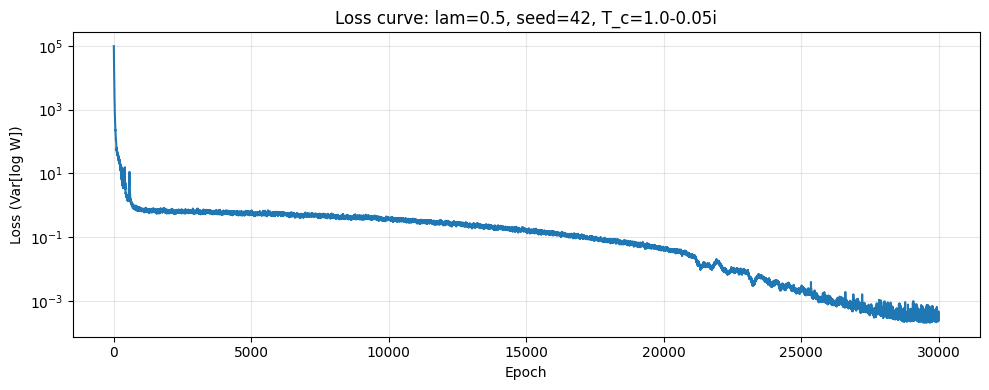

  Saved runs\20260706_161000_complextime_omega1.0_T1.0_eta0.05_N32_m1.0\loss_curve_seed42_lam0.5.png


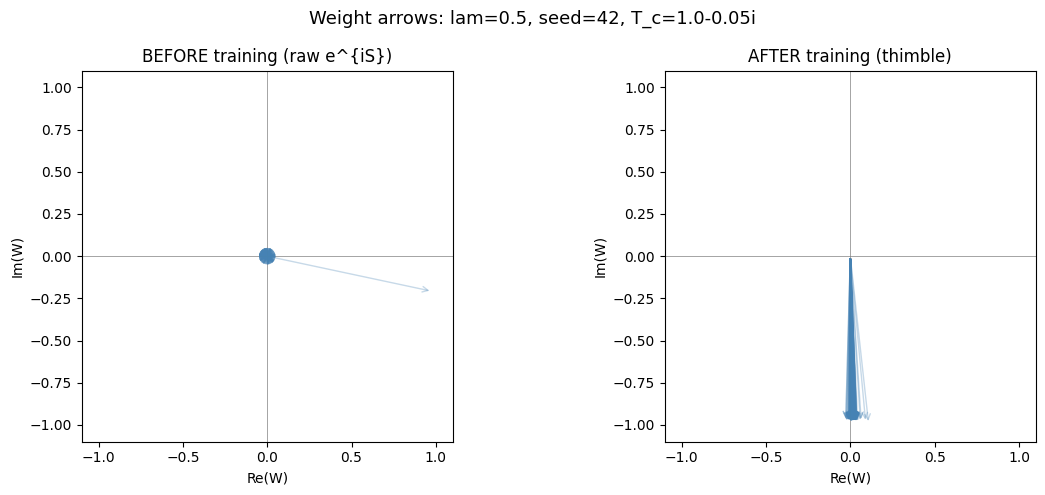

  Saved runs\20260706_161000_complextime_omega1.0_T1.0_eta0.05_N32_m1.0\arrows_seed42_lam0.5.png

----------------------------------------------------------------------
SEED 42 SUMMARY
----------------------------------------------------------------------
       lam            K_re            K_im         |K|        loss     ESS
  --------  --------------  --------------  ----------  ----------  ------
    0.5000      0.31705537     -0.29829404    0.435320    2.66e-04  0.9997

  SEED 43   (2/2)

######################################################################
#  SEED 43  |  LAMBDA 1/1:  lam = 0.5
#  T_c = 1.0 - 0.05i,  epochs=30000,  N=32
######################################################################

    Epoch     1/30000 | loss = 1.034602e+05 | 0s
    Epoch  3000/30000 | loss = 5.456027e-01 | 115s
    Epoch  6000/30000 | loss = 5.542107e-01 | 221s
    Epoch  9000/30000 | loss = 3.775041e-01 | 341s
    Epoch 12000/30000 | loss = 2.799020e-01 | 802s
    Epoch 15000/30000 

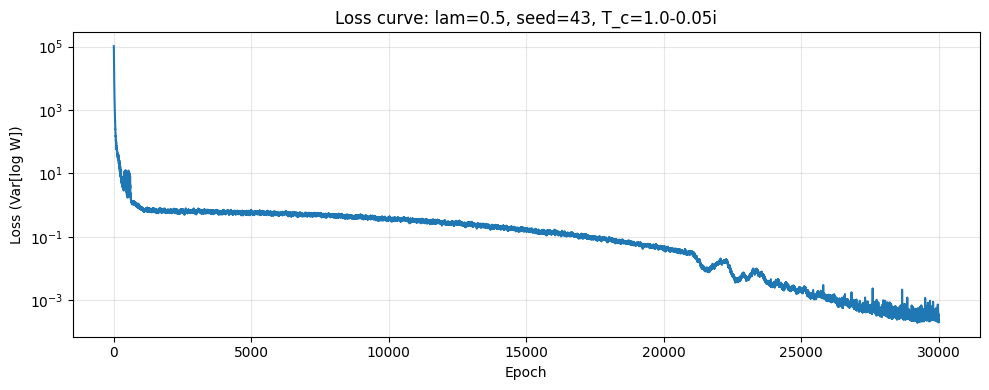

  Saved runs\20260706_161000_complextime_omega1.0_T1.0_eta0.05_N32_m1.0\loss_curve_seed43_lam0.5.png


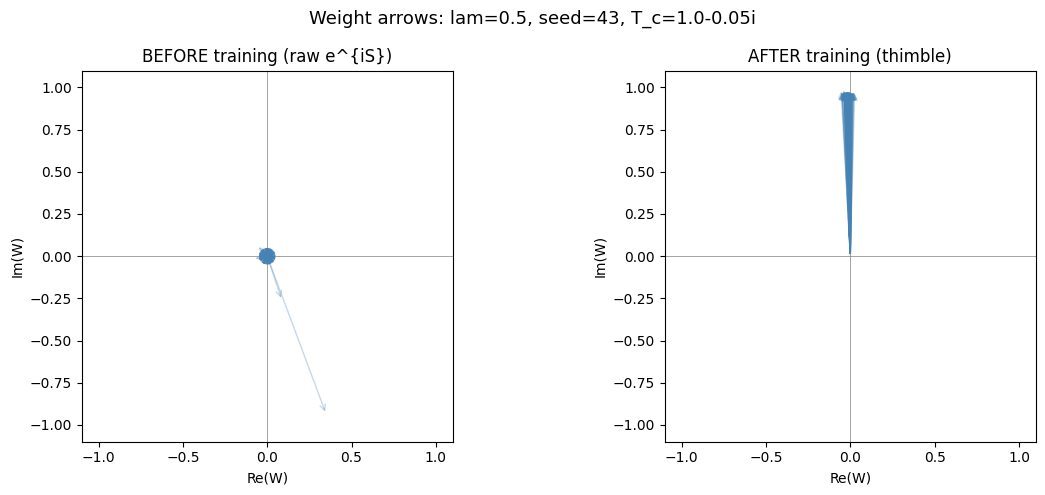

  Saved runs\20260706_161000_complextime_omega1.0_T1.0_eta0.05_N32_m1.0\arrows_seed43_lam0.5.png

----------------------------------------------------------------------
SEED 43 SUMMARY
----------------------------------------------------------------------
       lam            K_re            K_im         |K|        loss     ESS
  --------  --------------  --------------  ----------  ----------  ------
    0.5000     -0.31707784      0.29826355    0.435315    2.73e-04  0.9997

GRAND SUMMARY — all seeds × all lambdas
   seed       lam            K_re            K_im         |K|        loss     ESS
  -----  --------  --------------  --------------  ----------  ----------  ------
     42    0.5000      0.31705537     -0.29829404    0.435320    2.66e-04  0.9997

     43    0.5000     -0.31707784      0.29826355    0.435315    2.73e-04  0.9997

Mehler (lam=0): 0.3121370206-0.3022848712j  |K| = 0.43451774

All 2 results saved to runs\20260706_161000_complextime_omega1.0_T1.0_eta0.05_N32_m1.0

In [8]:
# ─────────────────────────────────────────────────────────────────────
#  SEED × LAMBDA LOOP — full lambda scan for each seed
# ─────────────────────────────────────────────────────────────────────

K_meh = mehler_kernel(x_i_prop, x_f_prop, T, m, omega, eta)

csv_path = os.path.join(run_dir, f"{run_tag}_all_endpoints.csv")
csv_header = ["seed", "lam", "K_re", "K_im", "abs_K", "std_err",
              "final_loss", "ess_n", "K_mehler_re", "K_mehler_im",
              "epochs", "N", "T", "eta", "m", "omega", "rank",
              "x_i", "x_f", "time_s"]
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    csv.writer(f).writerow(csv_header)

# all_results[(seed, lam)] = result dict
all_results = {}

for s_idx, seed in enumerate(seed_list):
    print(f"\n{'='*70}")
    print(f"  SEED {seed}   ({s_idx+1}/{len(seed_list)})")
    print(f"{'='*70}")

    for lam_idx, lam in enumerate(lambda_list):
        print(f"\n{'#'*70}")
        print(f"#  SEED {seed}  |  LAMBDA {lam_idx+1}/{len(lambda_list)}:  lam = {lam}")
        print(f"#  T_c = {T} - {eta}i,  epochs={epochs},  N={N}")
        print(f"{'#'*70}\n")

        result = run_single(
            lam, x_i=x_i_prop, x_f=x_f_prop,
            N_val=N, T_val=T, m_val=m, omega_val=omega, eta_val=eta,
            rank_val=rank, epochs_val=epochs, batch_val=batch,
            N_mc_val=N_mc, seed=seed,
        )
        all_results[(seed, lam)] = result

        K_ml = result['K_re'] + 1j * result['K_im']

        print("\n" + "-" * 50)
        print(f"  ML  K = {K_ml:.10f}   |K| = {abs(K_ml):.8f}")
        print(f"  Mehler (lam=0) = {K_meh:.10f}   |K| = {abs(K_meh):.8f}")
        if lam == 0:
            rel_err = abs(abs(K_ml) - abs(K_meh)) / abs(K_meh)
            print(f"  Relative error |K|:  {rel_err:.4e}")
        print(f"  Final loss = {result['final_loss']:.2e},  ESS/N = {result['ess_n']:.4f}")

        with open(csv_path, "a", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow([
                seed, f"{lam:.6g}",
                f"{result['K_re']:.16e}", f"{result['K_im']:.16e}",
                f"{result['abs_K']:.16e}", f"{result['std_err']:.6e}",
                f"{result['final_loss']:.6e}", f"{result['ess_n']:.6f}",
                f"{K_meh.real:.16e}", f"{K_meh.imag:.16e}",
                epochs, N, T, eta, m, omega, rank,
                x_i_prop, x_f_prop, f"{result['time_s']:.1f}"])

        # ── Loss curve ──
        plt.figure(figsize=(10, 4))
        plt.semilogy(result['loss_history'])
        plt.xlabel('Epoch')
        plt.ylabel('Loss (Var[log W])')
        plt.title(f'Loss curve: lam={lam}, seed={seed}, T_c={T}-{eta}i')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        fname = os.path.join(run_dir, f"loss_curve_seed{seed}_lam{lam}.png")
        plt.savefig(fname, dpi=150, bbox_inches='tight')
        plt.show()
        print(f"  Saved {fname}")

        # ── Arrow diagram ──
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        for ax, W, title in [
            (axes[0], result["W_before_norm"], "BEFORE training (raw e^{iS})"),
            (axes[1], result["W_after_norm"],  "AFTER training (thimble)"),
        ]:
            ax.set_aspect("equal")
            for w in W:
                ax.annotate("", xy=(w.real, w.imag), xytext=(0, 0),
                            arrowprops=dict(arrowstyle="->", color="steelblue", alpha=0.3))
            ax.set_xlim(-1.1, 1.1)
            ax.set_ylim(-1.1, 1.1)
            ax.axhline(0, color="grey", lw=0.5)
            ax.axvline(0, color="grey", lw=0.5)
            ax.set_xlabel("Re(W)")
            ax.set_ylabel("Im(W)")
            ax.set_title(title)
        fig.suptitle(f"Weight arrows: lam={lam}, seed={seed}, T_c={T}-{eta}i", fontsize=13)
        plt.tight_layout()
        fname = os.path.join(run_dir, f"arrows_seed{seed}_lam{lam}.png")
        plt.savefig(fname, dpi=150, bbox_inches="tight")
        plt.show()
        print(f"  Saved {fname}")

    # ── Per-seed summary ──
    print(f"\n{'-'*70}")
    print(f"SEED {seed} SUMMARY")
    print(f"{'-'*70}")
    print(f"  {'lam':>8s}  {'K_re':>14s}  {'K_im':>14s}  {'|K|':>10s}  {'loss':>10s}  {'ESS':>6s}")
    print(f"  {'-'*8}  {'-'*14}  {'-'*14}  {'-'*10}  {'-'*10}  {'-'*6}")
    for lam_val in lambda_list:
        res = all_results[(seed, lam_val)]
        print(f"  {lam_val:8.4f}  {res['K_re']:14.8f}  {res['K_im']:14.8f}  "
              f"{res['abs_K']:10.6f}  {res['final_loss']:10.2e}  {res['ess_n']:6.4f}")

# ── Grand summary — all seeds × all lambdas ──
print("\n" + "=" * 80)
print("GRAND SUMMARY — all seeds × all lambdas")
print("=" * 80)
print(f"  {'seed':>5s}  {'lam':>8s}  {'K_re':>14s}  {'K_im':>14s}  "
      f"{'|K|':>10s}  {'loss':>10s}  {'ESS':>6s}")
print(f"  {'-'*5}  {'-'*8}  {'-'*14}  {'-'*14}  {'-'*10}  {'-'*10}  {'-'*6}")
for seed in seed_list:
    for lam_val in lambda_list:
        res = all_results[(seed, lam_val)]
        print(f"  {seed:5d}  {lam_val:8.4f}  {res['K_re']:14.8f}  {res['K_im']:14.8f}  "
              f"{res['abs_K']:10.6f}  {res['final_loss']:10.2e}  {res['ess_n']:6.4f}")
    print()

print(f"Mehler (lam=0): {K_meh:.10f}  |K| = {abs(K_meh):.8f}")
print(f"\nAll {len(all_results)} results saved to {csv_path}")

### Combined |K| vs lambda plot

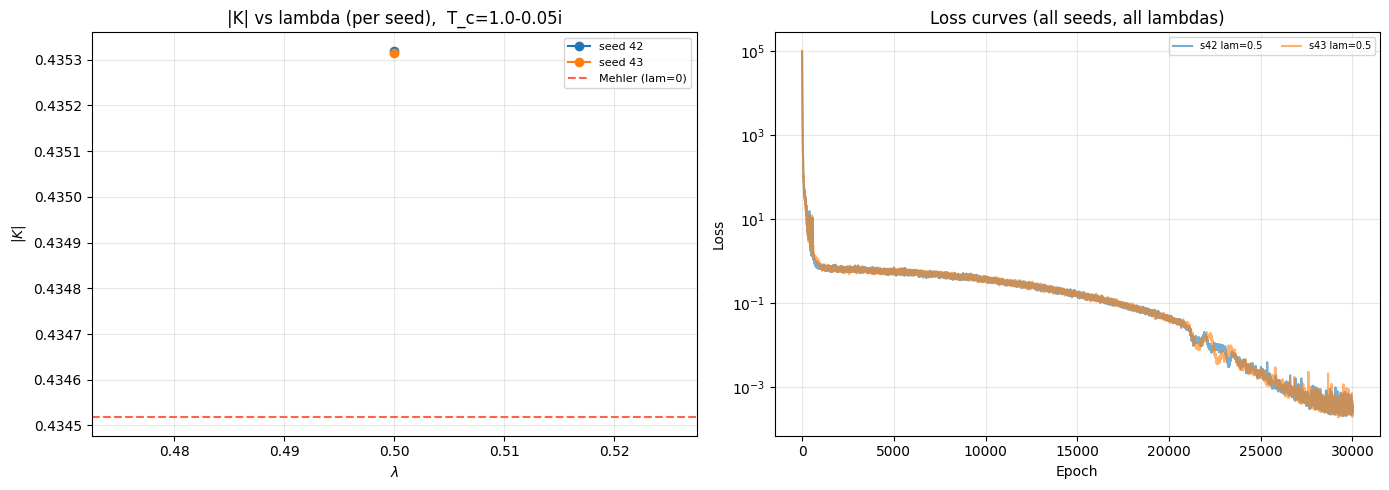

Saved runs\20260706_161000_complextime_omega1.0_T1.0_eta0.05_N32_m1.0\summary_K_vs_lambda.png


In [9]:
colors = plt.cm.tab10.colors
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for s_idx, seed in enumerate(seed_list):
    lams = sorted(lambda_list)
    abs_Ks = [all_results[(seed, l)]['abs_K'] for l in lams]
    c = colors[s_idx % len(colors)]
    axes[0].plot(lams, abs_Ks, 'o-', color=c, markersize=6, label=f'seed {seed}')

    for l in lams:
        axes[1].semilogy(all_results[(seed, l)]['loss_history'],
                         color=c, alpha=0.6,
                         label=f's{seed} lam={l}' if l == lams[0] else None)

axes[0].axhline(abs(K_meh), color='tomato', ls='--', lw=1.5, label='Mehler (lam=0)')
axes[0].set_xlabel(r'$\lambda$')
axes[0].set_ylabel(r'$|K|$')
axes[0].set_title(f'|K| vs lambda (per seed),  T_c={T}-{eta}i')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title('Loss curves (all seeds, all lambdas)')
axes[1].legend(fontsize=7, ncol=2)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fname = os.path.join(run_dir, "summary_K_vs_lambda.png")
plt.savefig(fname, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved {fname}")

## 7. Sanity Check: $\lambda=0$ ML vs Mehler

In [10]:
lam0_results = [(s, all_results[(s, 0.0)]) for s in seed_list if (s, 0.0) in all_results]

if lam0_results:
    K_meh_0 = mehler_kernel(x_i_prop, x_f_prop, T, m, omega, eta)
    print("=" * 70)
    print("LAMBDA = 0   SANITY CHECK  (all seeds)")
    print("=" * 70)
    for seed_val, res in lam0_results:
        K_ml_0 = res["K_re"] + 1j * res["K_im"]
        rel_err_abs = abs(abs(K_ml_0) - abs(K_meh_0)) / abs(K_meh_0)
        passed = rel_err_abs < 0.05
        status = "PASS" if passed else "FAIL"
        print(f"  seed {seed_val:5d}:  K = {K_ml_0:.10f}  abs(K) = {abs(K_ml_0):.8f}"
              f"  rel_err = {rel_err_abs:.4e}  [{status}]")
    print(f"\n  Mehler K = {K_meh_0:.10f}   abs(K) = {abs(K_meh_0):.8f}")
    print(f"  (threshold: 5% relative error on abs(K))")
else:
    print("lambda=0 not in lambda_list — skipping sanity check.")
    print("Add 0.0 to lambda_list to enable.")

lambda=0 not in lambda_list — skipping sanity check.
Add 0.0 to lambda_list to enable.
